# Exercise 63 – A GNN for a real material: pyroxene

**Week 13 · Graph neural networks**

The dataset contains structures of a pyroxene mineral built from oxygen
(Z = 8), magnesium (Z = 12) and silicon (Z = 14) atoms, with their energies.

* **Nodes** start from a 4-dimensional embedding of the element.
* **Edges** connect atoms closer than $r_c = 3.5$ Å and carry the weight
  $e_{ij} = \frac{1}{r_{ij}}\left[\tfrac12\cos(\pi r_{ij}/r_c) + \tfrac12\right]$,
  which goes smoothly to zero at the cutoff.
* Four message-passing layers build atomic representations, a small MLP turns
  each into a local energy, and the local energies are summed.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from matplotlib import patches
from sklearn.decomposition import PCA
from torch import nn
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.nn import global_add_pool

from comphy import DATA_DIR
from comphy.graphs import PhiPsiConv, edges_within_cutoff
from comphy.plotting import parity_plot
from comphy.training import evaluate, predict, train

np.random.seed(0)
torch.manual_seed(0)

data = np.load(DATA_DIR / "exercise_63" / "pyroxene.npz")
print({key: data[key].shape for key in data})

{'positions': (1906, 20, 2), 'z_vals': (1906, 20), 'energies': (1906,)}


## Building the graphs

In [2]:
SPECIES = {8: 0, 12: 1, 14: 2}             # Z -> embedding index
EMBEDDING_DIM = 4
CUTOFF = 3.5
embedding = nn.Embedding(len(SPECIES), EMBEDDING_DIM)   # random, fixed embedding


def get_graph(index):
    pos = torch.tensor(data["positions"][index], dtype=torch.float32)
    z = torch.tensor(data["z_vals"][index])
    edge_index = edges_within_cutoff(pos, CUTOFF)
    r = (pos[edge_index[0]] - pos[edge_index[1]]).norm(dim=1)
    edge_attr = (1 / r * (0.5 * torch.cos(np.pi * r / CUTOFF) + 0.5)).view(-1, 1)
    with torch.no_grad():
        x = embedding(torch.tensor([SPECIES[int(zi)] for zi in z]))
    return Data(x=x, pos=pos, z=z, edge_index=edge_index, edge_attr=edge_attr,
                y=torch.tensor(float(data["energies"][index])))


graphs = [get_graph(i) for i in range(len(data["positions"]))]
print(f"{len(graphs)} structures, e.g. {graphs[0]}")

1906 structures, e.g. Data(x=[20, 4], edge_index=[2, 110], edge_attr=[110, 1], y=-117.41212463378906, pos=[20, 2], z=[20])


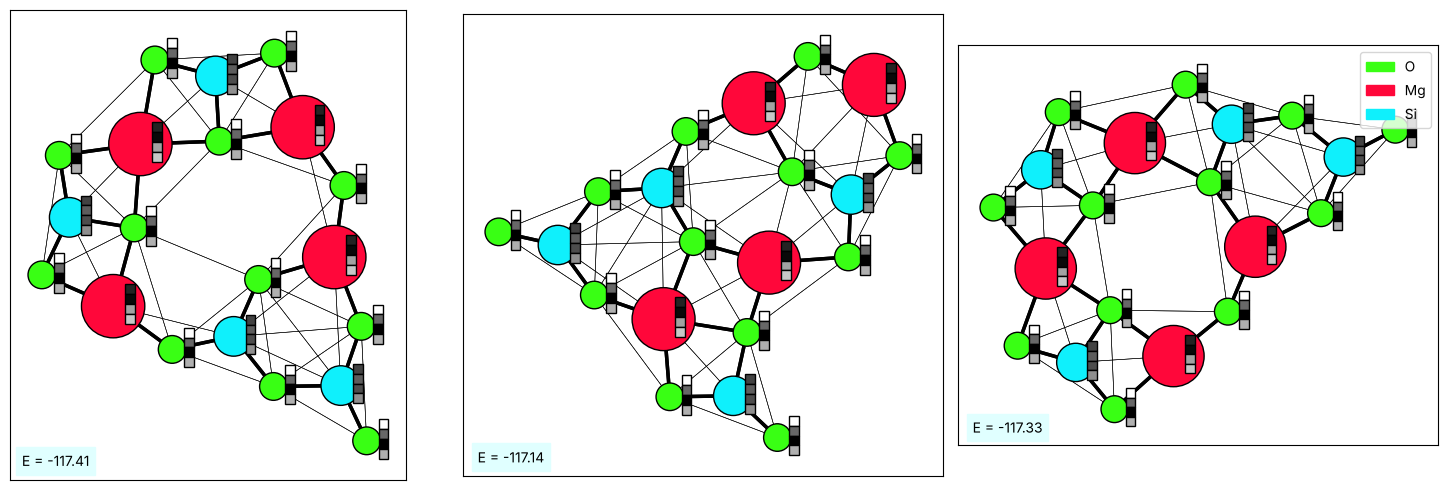

In [3]:
COLORS = {8: "#39FF14", 12: "#FF073A", 14: "#0FF0FC"}
RADII = {8: 0.35, 12: 0.8, 14: 0.5}


def plot_structure(ax, graph, features=None, vmin=-1.5, vmax=1.5):
    """Atoms as circles; optional grey boxes show the node feature vector."""
    pos = graph.pos[:, :2].numpy()
    for (i, j), w in zip(graph.edge_index.T.tolist(), graph.edge_attr.flatten().tolist()):
        ax.plot(pos[[i, j], 0], pos[[i, j], 1], color="black", lw=2.5 if w > 0.1 else 0.4, zorder=0)
    for k, (p, z) in enumerate(zip(pos, graph.z.tolist())):
        ax.add_patch(patches.Circle(p, RADII[z], facecolor=COLORS[z], edgecolor="black", zorder=1))
        if features is not None:
            for m, v in enumerate(features[k].tolist()):
                shade = min(1, max(0, (v - vmin) / (vmax - vmin)))
                ax.add_patch(patches.Rectangle((p[0] + 0.3, p[1] + 0.3 - 0.25 * m), 0.25, 0.25,
                                               color=str(shade), ec="black", zorder=2))
    ax.set(aspect="equal", xticks=[], yticks=[])
    ax.autoscale_view()
    ax.text(0.03, 0.03, f"E = {graph.y.item():.2f}", transform=ax.transAxes,
            backgroundcolor="lightcyan")


fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, g in zip(axes, graphs):
    plot_structure(ax, g, features=g.x)
handles = [patches.Patch(color=c, label=name) for c, name in zip(COLORS.values(), ["O", "Mg", "Si"])]
axes[-1].legend(handles=handles, loc="upper right")
fig.tight_layout()
plt.show()

## The model

In [4]:
class PyroxeneGNN(nn.Module):
    def __init__(self, d_hidden=4):
        super().__init__()
        d = EMBEDDING_DIM
        self.convs = nn.ModuleList([PhiPsiConv(d, d_hidden, d_message=d_hidden),
                                    PhiPsiConv(d_hidden, d, d_message=d_hidden),
                                    PhiPsiConv(d, d_hidden, d_message=d_hidden),
                                    PhiPsiConv(d_hidden, d, d_message=d_hidden)])
        self.readout = nn.Sequential(nn.Linear(d, d_hidden), nn.SiLU(),
                                     nn.Linear(d_hidden, d_hidden), nn.SiLU(),
                                     nn.Linear(d_hidden, 1))

    def representation(self, data):
        x = data.x
        for conv in self.convs:
            x = F.silu(conv(x, data.edge_index, data.edge_attr))
        return x

    def local_energies(self, data):
        return self.readout(self.representation(data))

    def forward(self, data):
        batch = data.batch if data.batch is not None else torch.zeros(data.num_nodes, dtype=torch.long)
        return global_add_pool(self.local_energies(data), batch).flatten()

## Training
85 % of the structures for training, 15 % for validation.

In [5]:
n_train = int(0.85 * len(graphs))
train_loader = DataLoader(graphs[:n_train], batch_size=30, shuffle=True)
val_loader = DataLoader(graphs[n_train:], batch_size=30)

model = PyroxeneGNN()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=1e-5)
history = train(model, train_loader, val_loader, epochs=300, optimizer=optimizer,
                print_every=25, restore_best=True)

epoch     0  train loss 6448  val loss 27.29


epoch    25  train loss 6.48  val loss 5.919


epoch    50  train loss 2.593  val loss 2.27


epoch    75  train loss 1.755  val loss 2.664


epoch   100  train loss 1.414  val loss 1.576


...

epoch   175  train loss 1.579  val loss 1.154


epoch   200  train loss 1.198  val loss 1.932


epoch   225  train loss 1.435  val loss 1.751


epoch   250  train loss 1.154  val loss 1.485


epoch   275  train loss 0.9729  val loss 0.9355


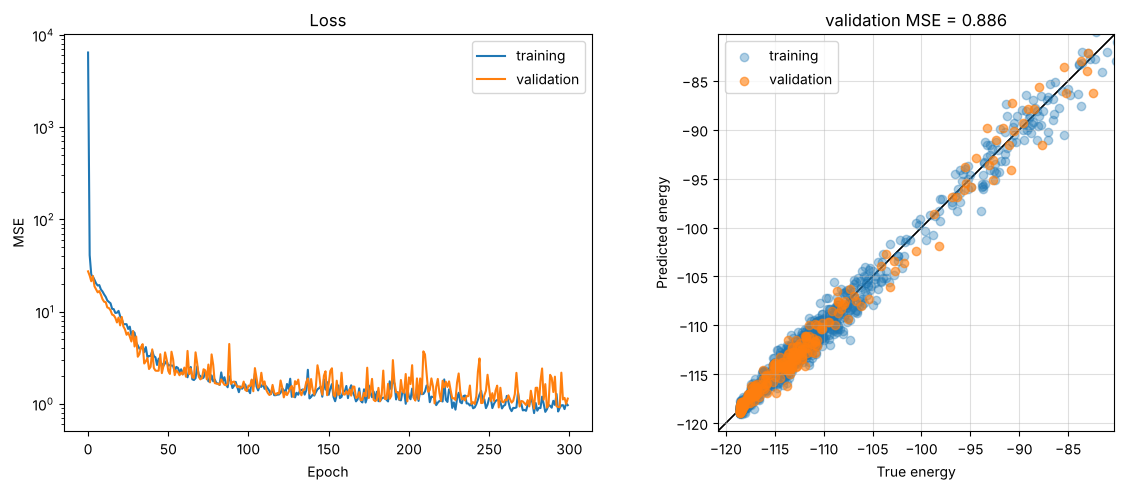

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].plot(history["train"], label="training")
axes[0].plot(history["val"], label="validation")
axes[0].set(xlabel="Epoch", ylabel="MSE", yscale="log", title="Loss")
axes[0].legend()
parity_plot(axes[1], *predict(model, DataLoader(graphs[:n_train], batch_size=64)),
            label="training", alpha=0.35)
parity_plot(axes[1], *predict(model, val_loader), label="validation", color="C1", alpha=0.6)
axes[1].set_title(f"validation MSE = {evaluate(model, val_loader):.3g}")
axes[1].legend()
fig.tight_layout()
plt.show()

## What did the network learn?
The final atomic representations of three validation structures:

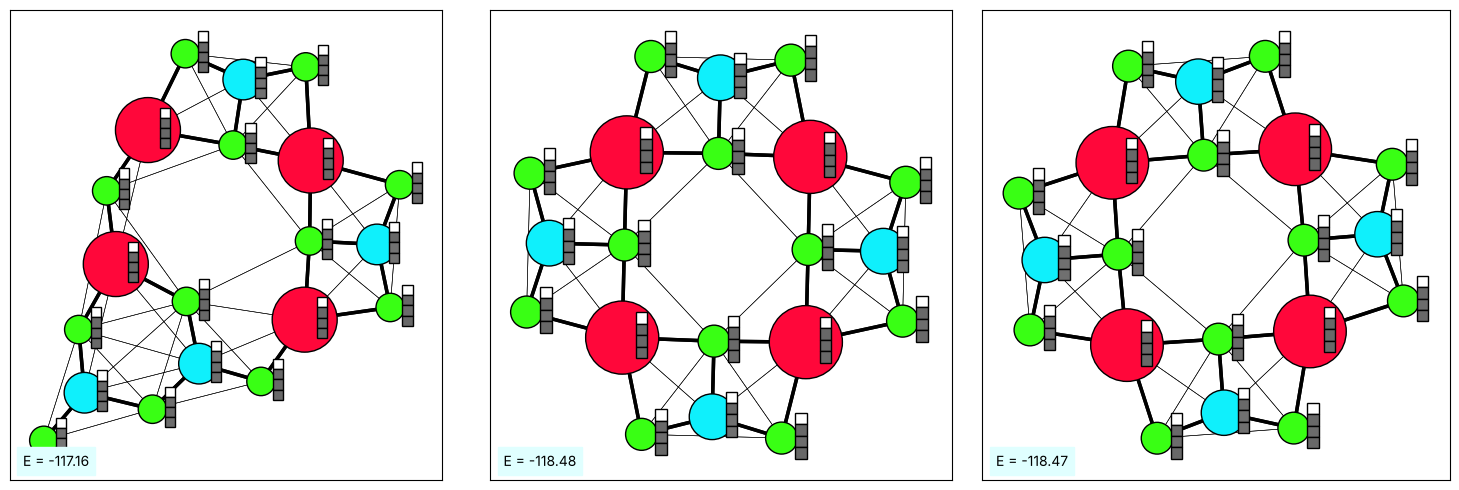

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
with torch.no_grad():
    for ax, g in zip(axes, graphs[-3:]):
        plot_structure(ax, g, features=model.representation(g))
fig.tight_layout()
plt.show()

A PCA of the representation vectors of all atoms, coloured by element.

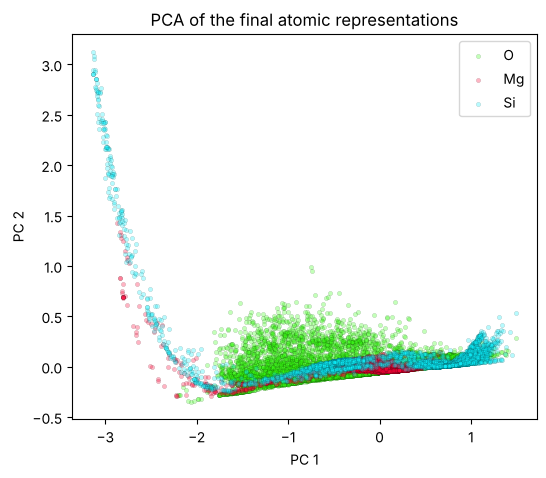

In [8]:
with torch.no_grad():
    reps = torch.cat([model.representation(g) for g in graphs]).numpy()
z_all = torch.cat([g.z for g in graphs]).numpy()
reps_2d = PCA(n_components=2).fit_transform(reps)

fig, ax = plt.subplots(figsize=(6, 5))
for z, name in zip(COLORS, ["O", "Mg", "Si"]):
    sel = z_all == z
    ax.scatter(*reps_2d[sel].T, s=10, alpha=0.3, color=COLORS[z], edgecolor="black", lw=0.2,
               label=name)
ax.set(xlabel="PC 1", ylabel="PC 2", title="PCA of the final atomic representations")
ax.legend()
plt.show()

Oxygen atoms mostly occupy their own region of the map, while magnesium and
silicon overlap strongly. The network was only trained to predict *total*
energies, so its atomic representations are organised by what matters for
the energy – the local environment – rather than strictly by element.